## Assignment 2 — Question 2: Motion or Memory?

## 0. Colab Setup

In [ ]:
# Environment setup for Google Colab (does nothing when run locally)
import os
import sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Question2')
    !pip install -q opencv-python imageio torchvision pandas
    sys.path.insert(0, os.getcwd())
print(f"Working directory: {os.getcwd()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/Question2


## 0. Environment and Shared Helpers

In [ ]:
import glob
import json
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from q2.data import WindowSampler, load_split, to_float
from q2.evaluate import (TRANSFORMS, fmt, fmt_seeds, full_evaluation, get_device,
                         inference_time, predict, test_windows)
from q2.models import (D_CANDIDATES, D_CHOICE, PROTOCOLS, Blank, CopyLast, Symmetrised,
                       build, ckpt_stem, empirical_reach, load_checkpoint, n_params)
from q2.train import hardware_string, train
from q2.transforms import G, G_NAMES, mirror, rotate, window
from q2.viz import (FIG_DIR, GIF_DIR, figure5_frames, first_clean_video, make_figure2,
                    make_figure3_panel, make_figure5, n_digit_blobs)

RES_DIR, CKPT_DIR, LOG_DIR = Path("results"), Path("checkpoints"), Path("results/train_logs")
for d in (RES_DIR, FIG_DIR, GIF_DIR):
    d.mkdir(parents=True, exist_ok=True)
SEEDS = (0, 1)

device = get_device()
print(f"PyTorch {torch.__version__}, device: {device}")
print(f"Hardware used for every inference timing in this run: {hardware_string(device)}")


def save_json(name, obj):
    with open(RES_DIR / name, "w") as f:
        json.dump(obj, f, indent=1, ensure_ascii=False)


def train_if_missing(model_name, seed):
    """Train one model (q2.train.train) only if its checkpoint does not exist."""
    ckpt = CKPT_DIR / f"{ckpt_stem(model_name)}_s{seed}.pt"
    if ckpt.exists():
        print(f"{ckpt} exists: not retraining.")
    else:
        train(model_name, seed)


def load_model(model_name, seed):
    return load_checkpoint(CKPT_DIR / f"{ckpt_stem(model_name)}_s{seed}.pt", device)


EV = {}


def evaluate(name, seed=None, model=None):
    """Full test-split evaluation of one forecaster, computed once and cached."""
    if (name, seed) not in EV:
        EV[(name, seed)] = full_evaluation(model if model is not None else load_model(name, seed), device)
    return EV[(name, seed)]


test_vids = to_float(load_split("test"))
X1, Y1, _ = test_windows(1, 1, "test")
print(f"Test videos: {tuple(test_vids.shape)}; 1x windows X {tuple(X1.shape)}, Y {tuple(Y1.shape)}")

PyTorch 2.11.0+cu130, device: cuda
Hardware used for every inference timing in this run: NVIDIA RTX PRO 6000 Blackwell Server Edition
Test videos: (1000, 20, 1, 64, 64); 1x windows X (1000, 5, 1, 64, 64), Y (1000, 5, 1, 64, 64)


---
## 1. Setup, Data Statistics, and Transformation Checks

### 1.1 Implementation Sanity Checks (Table 1)

In [ ]:
def bright(v):
    idx = torch.nonzero(v == v.max())
    assert len(idx) == 1
    f, _, r, c = idx[0].tolist()
    return (f, r, c)


def frames_str(k):
    v = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).expand(20, 1, 64, 64)
    X, Y, mask = window(v, 1, k)
    fx = [int(f) for f in X[:, 0, 0, 0]]
    fy = [int(f) for f, m in zip(Y[:, 0, 0, 0], mask) if m > 0]
    rng = lambda l: f"{l[0]}–{l[-1]}" if len(l) > 2 and l == list(range(l[0], l[-1] + 1)) else ", ".join(map(str, l))
    return f"{rng(fx)} / {rng(fy)}"


def exact(a, b):
    return f"{(a - b).abs().max().item():g} (torch.equal={torch.equal(a, b)})"


torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64)
p[7, 0, 10, 20] = 1
table1 = [
    ("(a)", "max|M(M(x)) − x|", "0", exact(mirror(mirror(x)), x)),
    ("(b)", "max|R^4(x) − x|", "0", exact(rotate(x, 4), x)),
    ("(c)", "max|MRM(x) − R^−1(x)|", "0", exact(mirror(rotate(mirror(x))), rotate(x, -1))),
    ("(d)", "bright pixel of M(p) (frame, row, column)", "(7, 10, 43)", str(bright(mirror(p)))),
    ("(e)", "bright pixel of R(p) (frame, row, column)", "(7, 43, 10)", str(bright(rotate(p)))),
    ("(f)", "1× input / target frames", "1–5 / 6–10", frames_str(1)),
    ("(g)", "2× input / target frames", "1, 3, 5, 7, 9 / 11, 13, 15, 17, 19", frames_str(2)),
    ("(h)", "3× input / target frames", "1, 4, 7, 10, 13 / 16, 19", frames_str(3)),
]
assert all(r[3].split(" (")[0] == r[2] for r in table1), "Table 1 mismatch: fix before continuing"
save_json("table1.json", table1)
display(pd.DataFrame(table1, columns=["", "Check", "Expected", "Yours"]))

,,Check,Expected,Yours
0,(a),max|M(M(x)) − x|,0,0 (torch.equal=True)
1,(b),max|R^4(x) − x|,0,0 (torch.equal=True)
2,(c),max|MRM(x) − R^−1(x)|,0,0 (torch.equal=True)
3,(d),"bright pixel of M(p) (frame, row, column)","(7, 10, 43)","(7, 10, 43)"
4,(e),"bright pixel of R(p) (frame, row, column)","(7, 43, 10)","(7, 43, 10)"
5,(f),1× input / target frames,1–5 / 6–10,1–5 / 6–10
6,(g),2× input / target frames,"1, 3, 5, 7, 9 / 11, 13, 15, 17, 19","1, 3, 5, 7, 9 / 11, 13, 15, 17, 19"
7,(h),3× input / target frames,"1, 4, 7, 10, 13 / 16, 19","1, 4, 7, 10, 13 / 16, 19"


### 1.2 Optical Flow & Trajectory Isotropy (Figure 1)

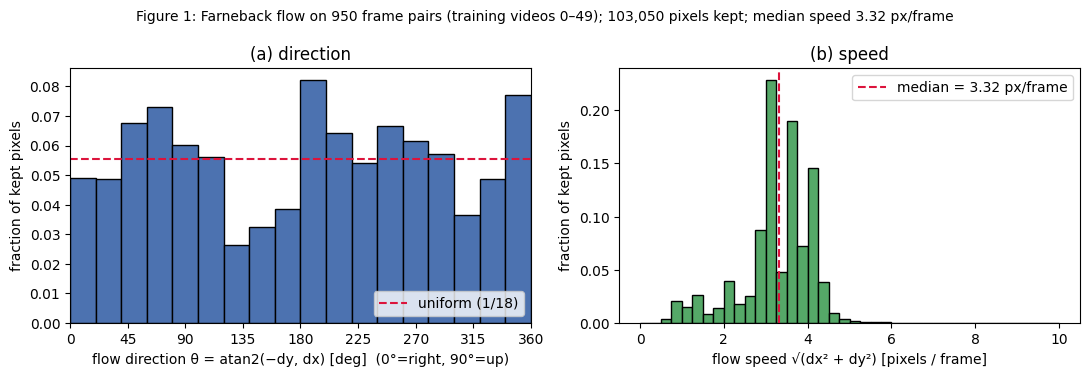

{'n_pairs': 950, 'n_kept': 103050, 'median_speed': 3.318, 'mean_speed': 3.271, 'p10': 2.142, 'p90': 4.124, 'p99': 4.674, 'dir_min': 0.026, 'dir_max': 0.082}
direction fractions: [0.049, 0.0488, 0.0675, 0.0731, 0.0602, 0.0561, 0.0263, 0.0326, 0.0384, 0.082, 0.0642, 0.0541, 0.0666, 0.0614, 0.0571, 0.0366, 0.0487, 0.0772]
speed x2: median 6.64, p99 9.35; speed x3: median 9.95, p99 14.02 px/frame


In [ ]:
# Figure 1: Farneback flow on the first 50 training videos (950 consecutive frame pairs)
train_u8 = load_split("train")
thetas, speeds = [], []
for v in train_u8[:50, :, 0].numpy():  # uint8 frames = round(255 x)
    for s in range(19):
        fl = cv2.calcOpticalFlowFarneback(v[s], v[s + 1], None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = fl[..., 0], fl[..., 1]
        mag = np.sqrt(dx ** 2 + dy ** 2)
        keep = (v[s] / 255.0 > 0.2) & (v[s + 1] / 255.0 > 0.2) & (mag > 0.5)
        thetas.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360.0)
        speeds.append(mag[keep])
theta, speed = np.concatenate(thetas), np.concatenate(speeds)
n, med = len(theta), float(np.median(speed))
bins = np.arange(0, 361, 20)
h_dir = np.histogram(theta, bins=bins)[0] / n

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(bins[:-1], h_dir, width=20, align="edge", color="#4c72b0", edgecolor="k")
ax[0].axhline(1 / 18, color="crimson", ls="--", label="uniform (1/18)")
ax[0].set(xticks=range(0, 361, 45), xlim=(0, 360), ylabel="fraction of kept pixels", title="(a) direction",
          xlabel="flow direction θ = atan2(−dy, dx) [deg]  (0°=right, 90°=up)")
ax[0].legend(loc="lower right")
ax[1].hist(speed, bins=np.linspace(0, max(10, np.percentile(speed, 99.5)), 41),
           weights=np.ones_like(speed) / n, color="#55a868", edgecolor="k")
ax[1].axvline(med, color="crimson", ls="--", label=f"median = {med:.2f} px/frame")
ax[1].set(xlabel="flow speed √(dx² + dy²) [pixels / frame]", ylabel="fraction of kept pixels", title="(b) speed")
ax[1].legend()
fig.suptitle(f"Figure 1: Farneback flow on 950 frame pairs (training videos 0–49); "
             f"{n:,} pixels kept; median speed {med:.2f} px/frame", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "figure1_flow.png", dpi=150)
plt.show()

flow_stats = dict(n_pairs=950, n_kept=n, median_speed=med, mean_speed=float(speed.mean()),
                  **{f"p{q}": float(np.percentile(speed, q)) for q in (10, 90, 99)},
                  dir_hist=h_dir.tolist(), dir_min=float(h_dir.min()), dir_max=float(h_dir.max()),
                  dir_hist_mirrored=h_dir[(8 - np.arange(18)) % 18].tolist())  # M: bin i -> (8 - i) mod 18
save_json("figure1_stats.json", flow_stats)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in flow_stats.items() if not k.startswith("dir_hist")})
print("direction fractions:", np.round(h_dir, 4).tolist())
print(f"speed x2: median {2 * med:.2f}, p99 {2 * flow_stats['p99']:.2f}; "
      f"speed x3: median {3 * med:.2f}, p99 {3 * flow_stats['p99']:.2f} px/frame")

---
## 2. Baseline ConvLSTM (Model A)

### 2.1 Architecture & Rollout Dynamics

In [ ]:
model_a = build("A")
assert n_params(model_a) == 480_784
print(f"Model A parameters: {n_params(model_a):,} (expected 480,784)")
print(f"Model A one-step reach: {model_a.reach_pixels()} px (analytic)")
print(f"Empirical reach per input source (px): {empirical_reach(model_a)}")

Model A parameters: 480,784 (expected 480,784)
Model A one-step reach: 8 px (analytic)
Empirical reach per input source (px): {'u_tau': 8, 'h1_prev': 8, 'c1_prev': 4, 'h2_prev': 4, 'c2_prev': 0}


### 2.2 Model A Training & 1× Baseline Evaluation (Table 2 & Figure 2)

In [ ]:
for s in SEEDS:
    train_if_missing("A", s)

[A_s0] params=480784 reach=8px speed_aug=False sym_aug=False device=cuda
[A_s0] epoch  1 loss 0.04611 val E5 0.03931 time 3.9s
[A_s0] epoch  2 loss 0.03967 val E5 0.03861 time 1.8s
[A_s0] epoch  3 loss 0.03865 val E5 0.03724 time 1.8s
[A_s0] epoch  4 loss 0.03712 val E5 0.03543 time 1.8s
[A_s0] epoch  5 loss 0.03531 val E5 0.03384 time 1.8s
[A_s0] epoch  6 loss 0.03367 val E5 0.03249 time 1.8s
[A_s0] epoch  7 loss 0.03224 val E5 0.03189 time 1.8s
[A_s0] epoch  8 loss 0.03124 val E5 0.03090 time 1.8s
[A_s0] epoch  9 loss 0.03040 val E5 0.02965 time 1.8s
[A_s0] epoch 10 loss 0.02971 val E5 0.02903 time 1.8s
[A_s0] epoch 11 loss 0.02928 val E5 0.02904 time 1.8s
[A_s0] epoch 12 loss 0.02873 val E5 0.02827 time 1.8s
[A_s0] epoch 13 loss 0.02833 val E5 0.02786 time 1.8s
[A_s0] epoch 14 loss 0.02796 val E5 0.02748 time 1.8s
[A_s0] epoch 15 loss 0.02750 val E5 0.02718 time 1.8s
[A_s0] epoch 16 loss 0.02719 val E5 0.02668 time 1.8s
[A_s0] epoch 17 loss 0.02680 val E5 0.02638 time 1.8s
[A_s0] ep

Table 2 (test split, 1x, t = 1). Model A: mean (seed 0, seed 1).


,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),# Params
0,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
1,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0
2,Model A,"0.0171 (0.0175, 0.0168)","0.0205 (0.0208, 0.0201)","0.0227 (0.0230, 0.0224)","0.0244 (0.0247, 0.0242)","0.0261 (0.0263, 0.0259)","0.0222 (0.0225, 0.0219)","480,784"


Figure 2, test video 0: digits touch/overlap in frames [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 14, 15, 16, 17, 18, 19, 20]
Figure 2, test video 1: digits touch/overlap in frames [7, 8, 9, 10, 11, 20]
Figure 2, test video 2: digits touch/overlap in frames [1, 8, 9, 10, 11, 12, 13]


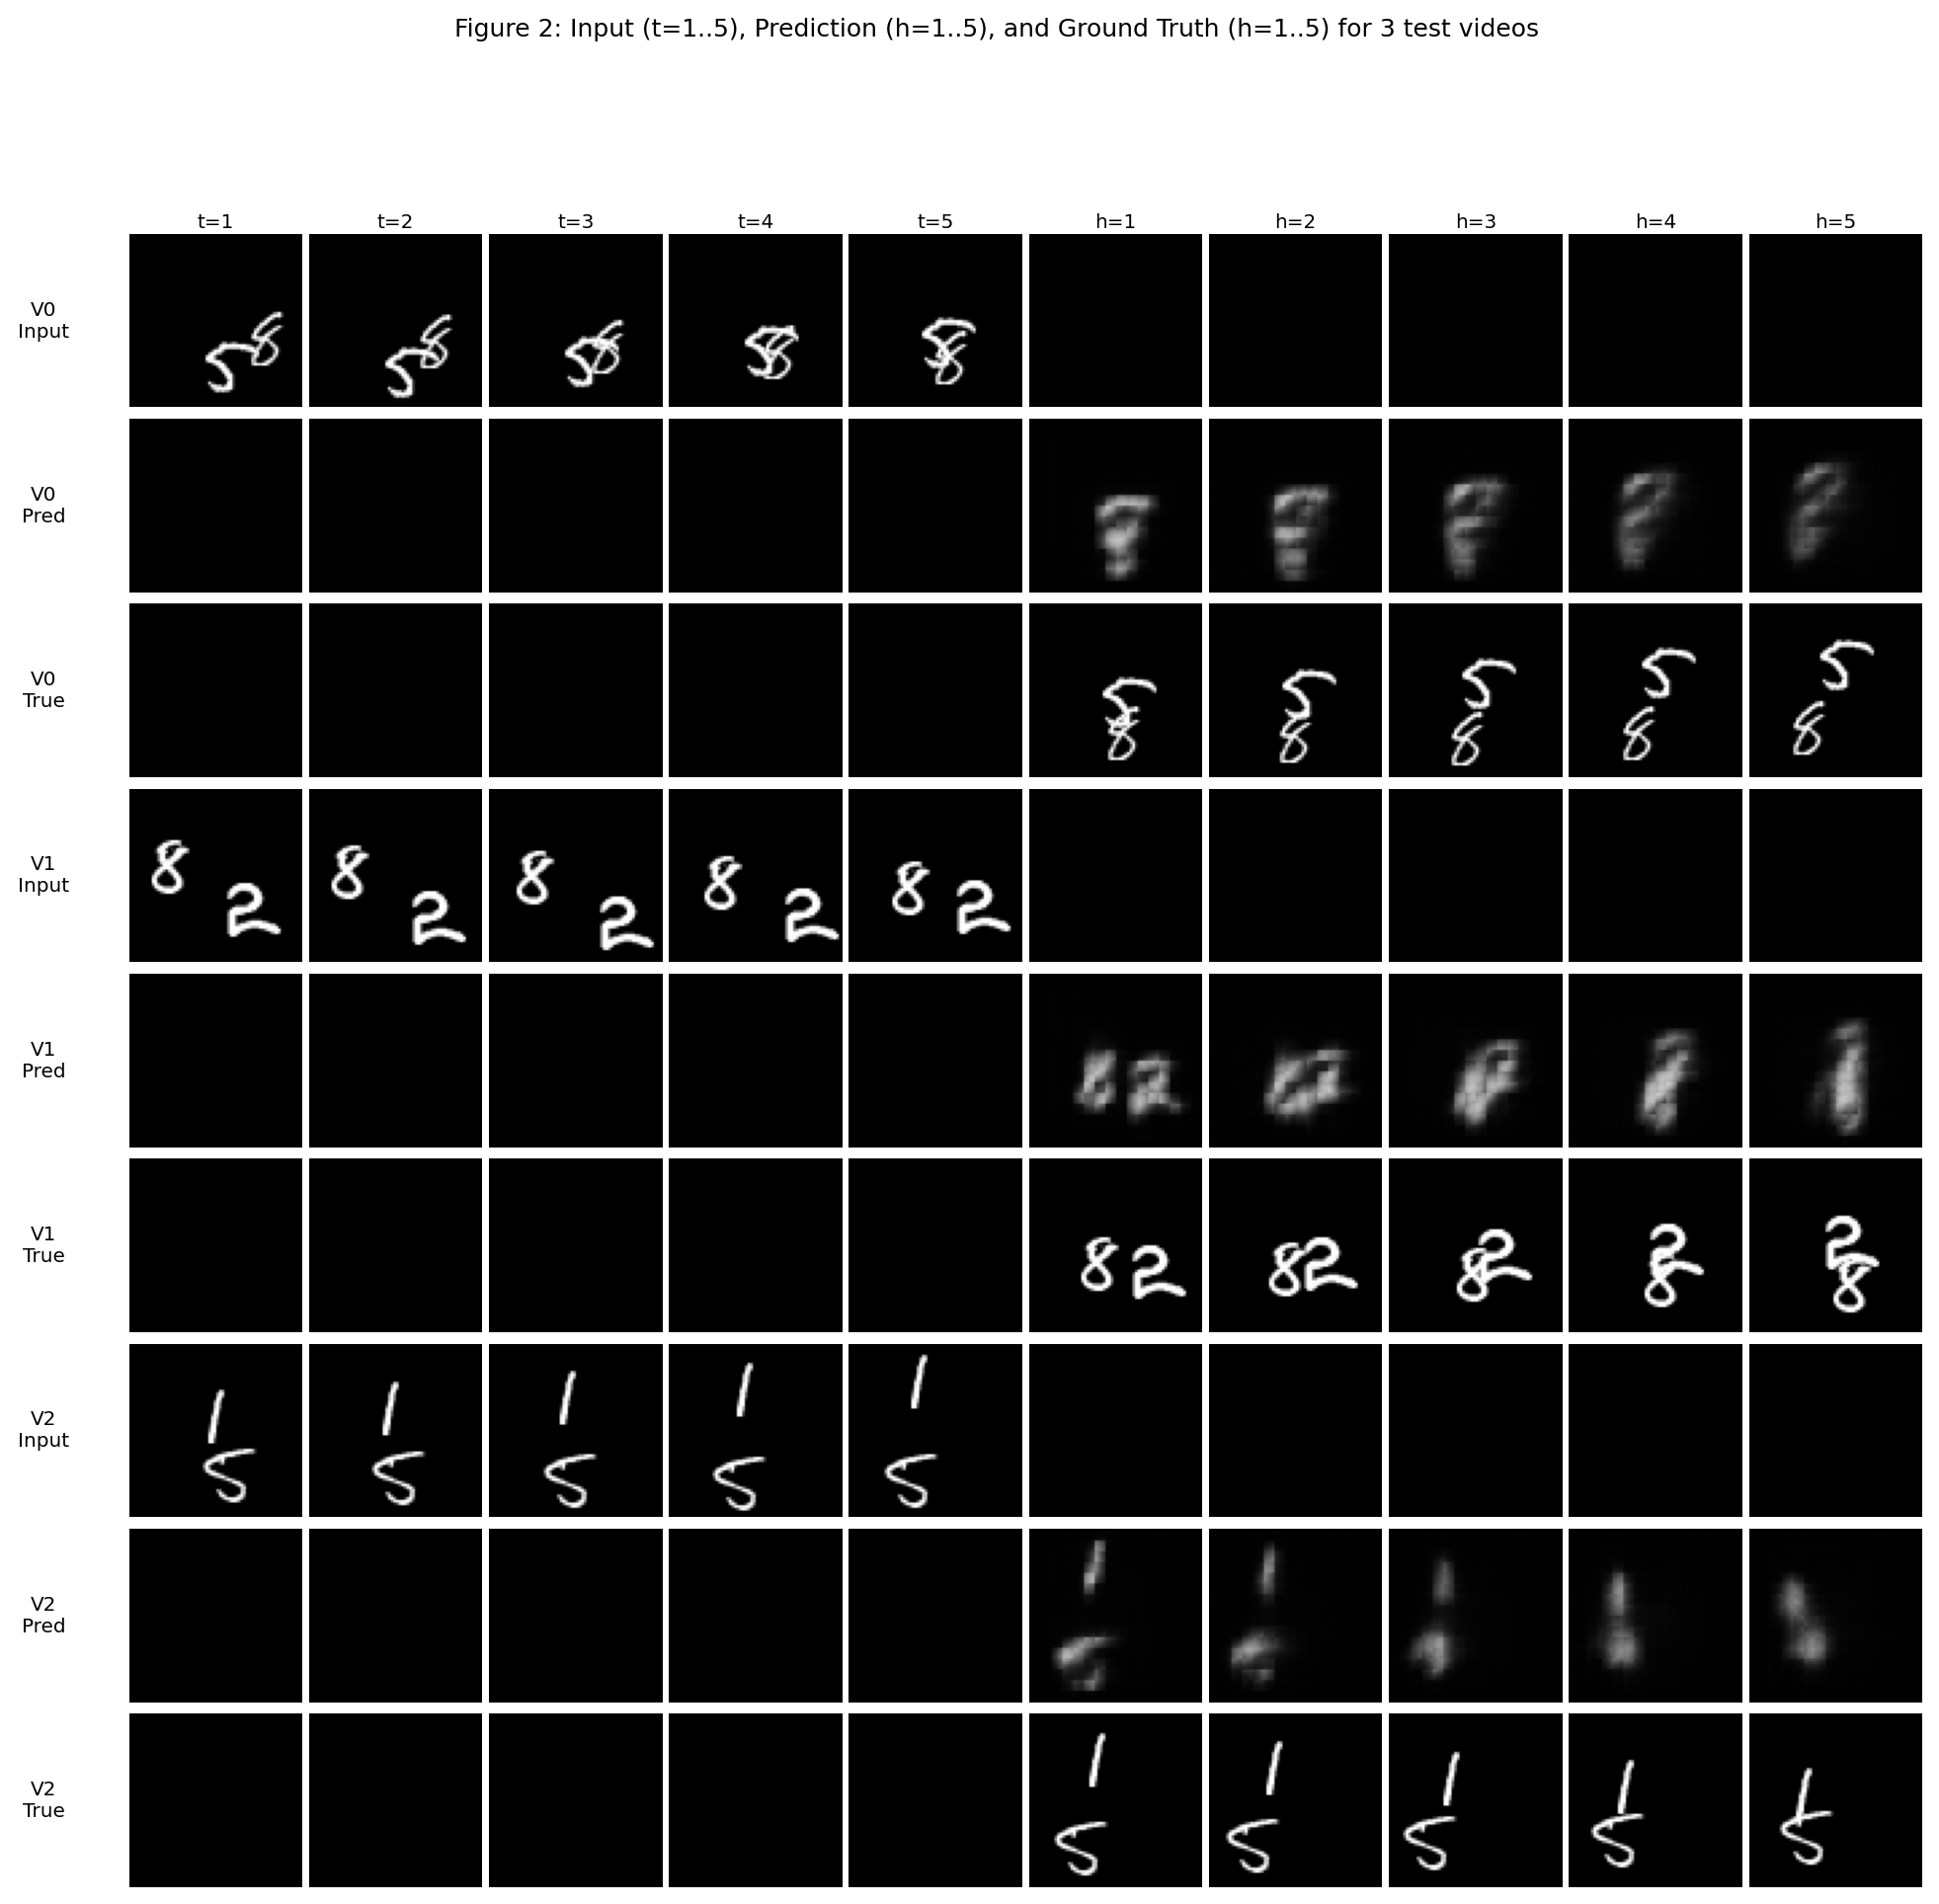

In [ ]:
REFS = {"Blank": Blank(), "Copy-last": CopyLast()}
for name, model in REFS.items():
    evaluate(name, model=model)
for s in SEEDS:
    evaluate("A", s)

t2 = {name: dict(MSE_h=EV[(name, None)][1]["MSE_h"], E5=EV[(name, None)][1]["E5_1x"], params=0) for name in REFS}
t2["Model A"] = [dict(seed=s, MSE_h=EV[("A", s)][1]["MSE_h"], E5=EV[("A", s)][1]["E5_1x"], params=480_784)
                 for s in SEEDS]
save_json("table2.json", t2)

rows = [[name] + [fmt(v) for v in d["MSE_h"]] + [fmt(d["E5"]), "0"] for name, d in t2.items() if name in REFS]
rows.append(["Model A"] + [fmt_seeds([d["MSE_h"][h] for d in t2["Model A"]]) for h in range(5)]
            + [fmt_seeds([d["E5"] for d in t2["Model A"]]), "480,784"])
print("Table 2 (test split, 1x, t = 1). Model A: mean (seed 0, seed 1).")
display(pd.DataFrame(rows, columns=["Model", "MSE1", "MSE2", "MSE3", "MSE4", "MSE5", "E(5)", "# Params"]))

A0 = load_model("A", 0)
fig2_videos = [0, 1, 2]
for v in fig2_videos:
    touching = [f for f in range(1, 21) if n_digit_blobs(test_vids[v, f - 1, 0].numpy()) < 2]
    print(f"Figure 2, test video {v}: digits touch/overlap in frames {touching}")
make_figure2(A0, test_vids, fig2_videos)
display(Image("figures/figure2_predictions.png"))

---
## 3. Testing the Baseline: Mirror, Rotation, and Faster Motion

In [ ]:
# Table 3: consistency gap and transformed error under mirror and rotation (1x, t = 1)
KEYS3 = ["E5_1x", "C_M", "E_M", "C_R", "E_R"]
t3 = {name: {k: EV[(name, None)][1][k] for k in KEYS3} for name in REFS}
t3["Model A"] = [dict(seed=s, **{k: EV[("A", s)][1][k] for k in KEYS3}) for s in SEEDS]
save_json("table3.json", t3)

rows = [[name] + [fmt(t3[name][k]) for k in KEYS3] for name in REFS]
rows.append(["Model A"] + [fmt_seeds([d[k] for d in t3["Model A"]]) for k in KEYS3])
print("Table 3 (test split, 1x, t = 1). Model A: mean (seed 0, seed 1).")
display(pd.DataFrame(rows, columns=["Model", "E(5)", "C_M", "E_M", "C_R", "E_R"]))

Table 3 (test split, 1x, t = 1). Model A: mean (seed 0, seed 1).


,Model,E(5),C_M,E_M,C_R,E_R
0,Blank,0.0426,0,0.0426,0,0.0426
1,Copy-last,0.0641,0,0.0641,0,0.0641
2,Model A,"0.0222 (0.0225, 0.0219)","0.00186 (0.00161, 0.00211)","0.0228 (0.0230, 0.0225)","0.00298 (0.00268, 0.00329)","0.0239 (0.0240, 0.0238)"


### 3.1 Qualitative Failure Analysis (Figure 3 & Figure 4)

Top-2 C_M videos: [499, 329] (values: [0.004631437826901674, 0.004188138525933027])
Top-2 C_R videos: [279, 733] (values: [0.007181954570114613, 0.006528843194246292])


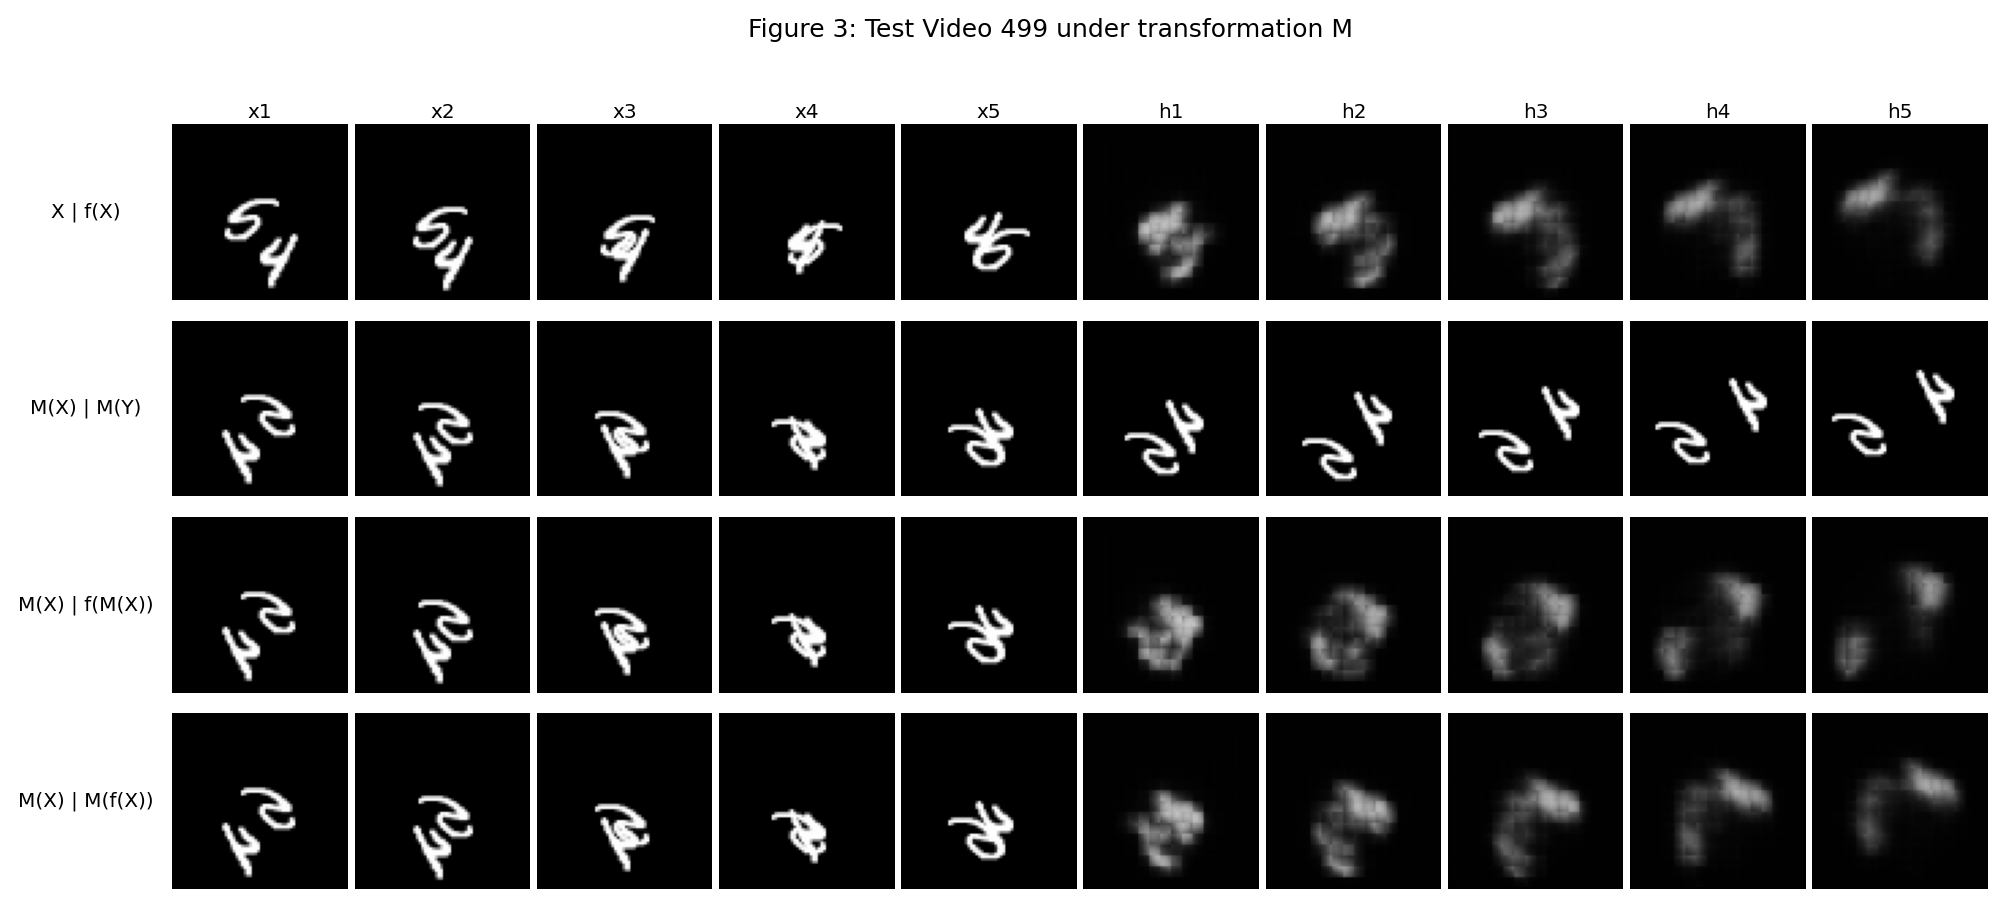

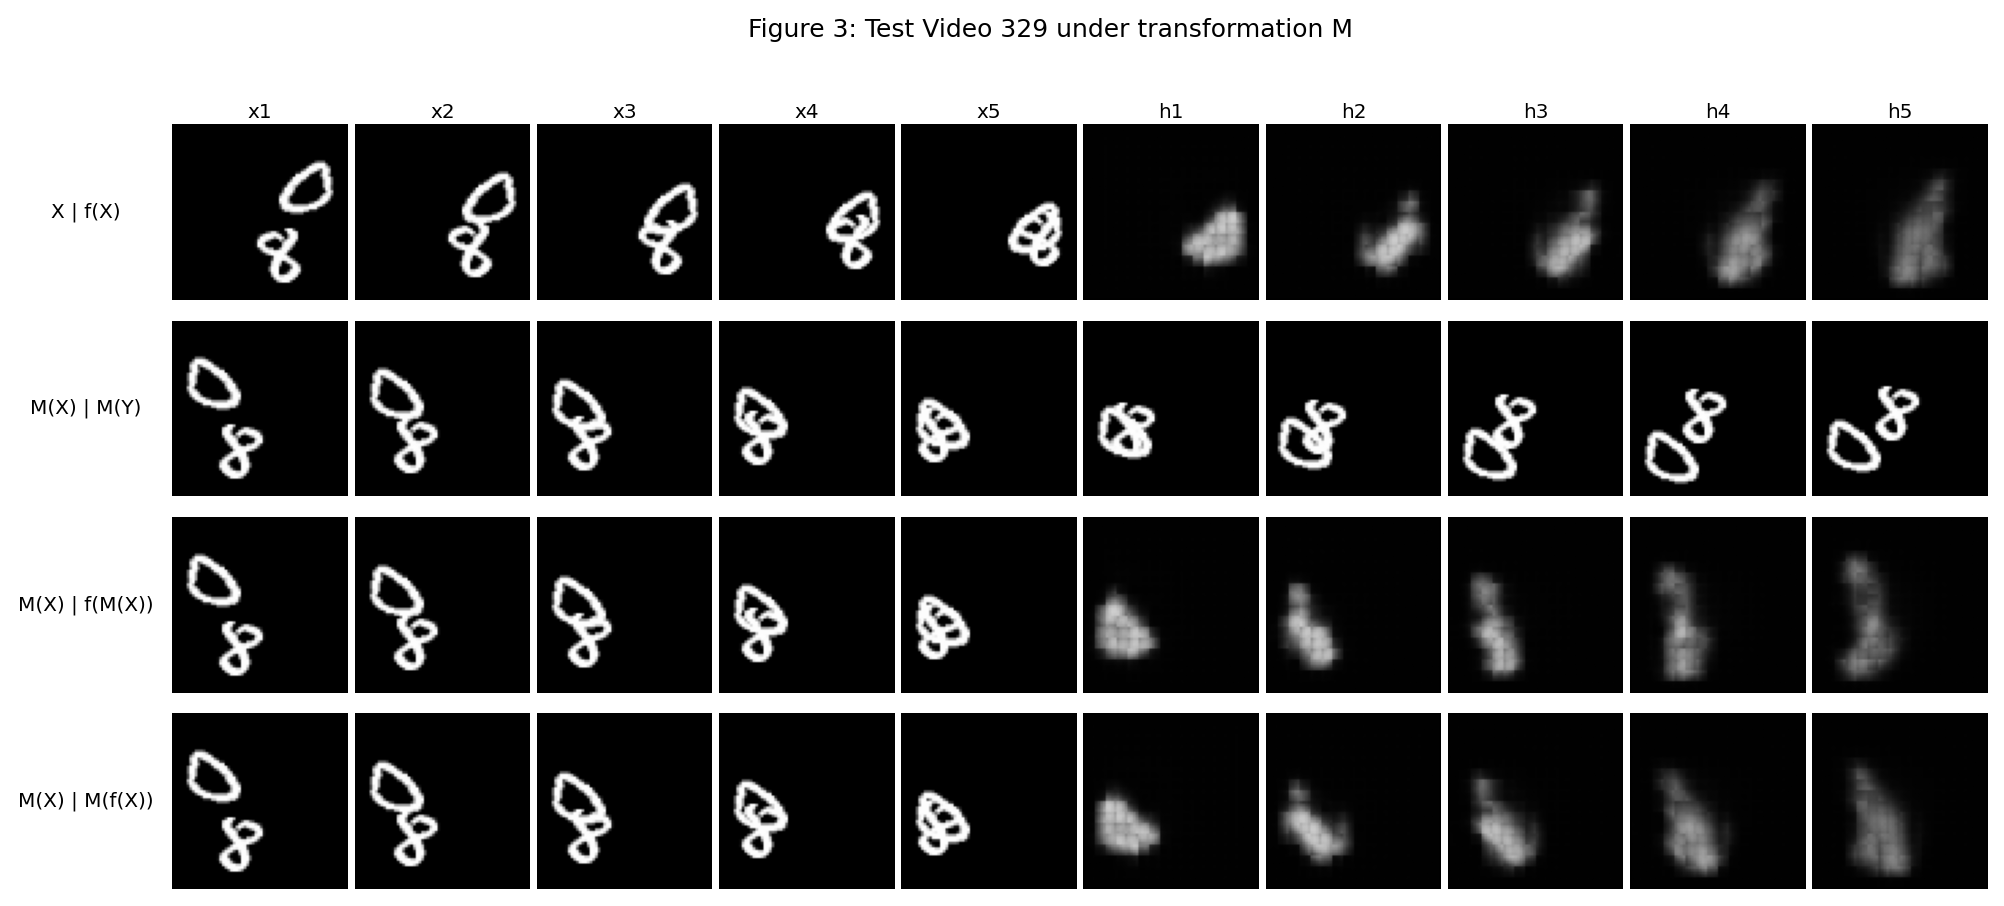

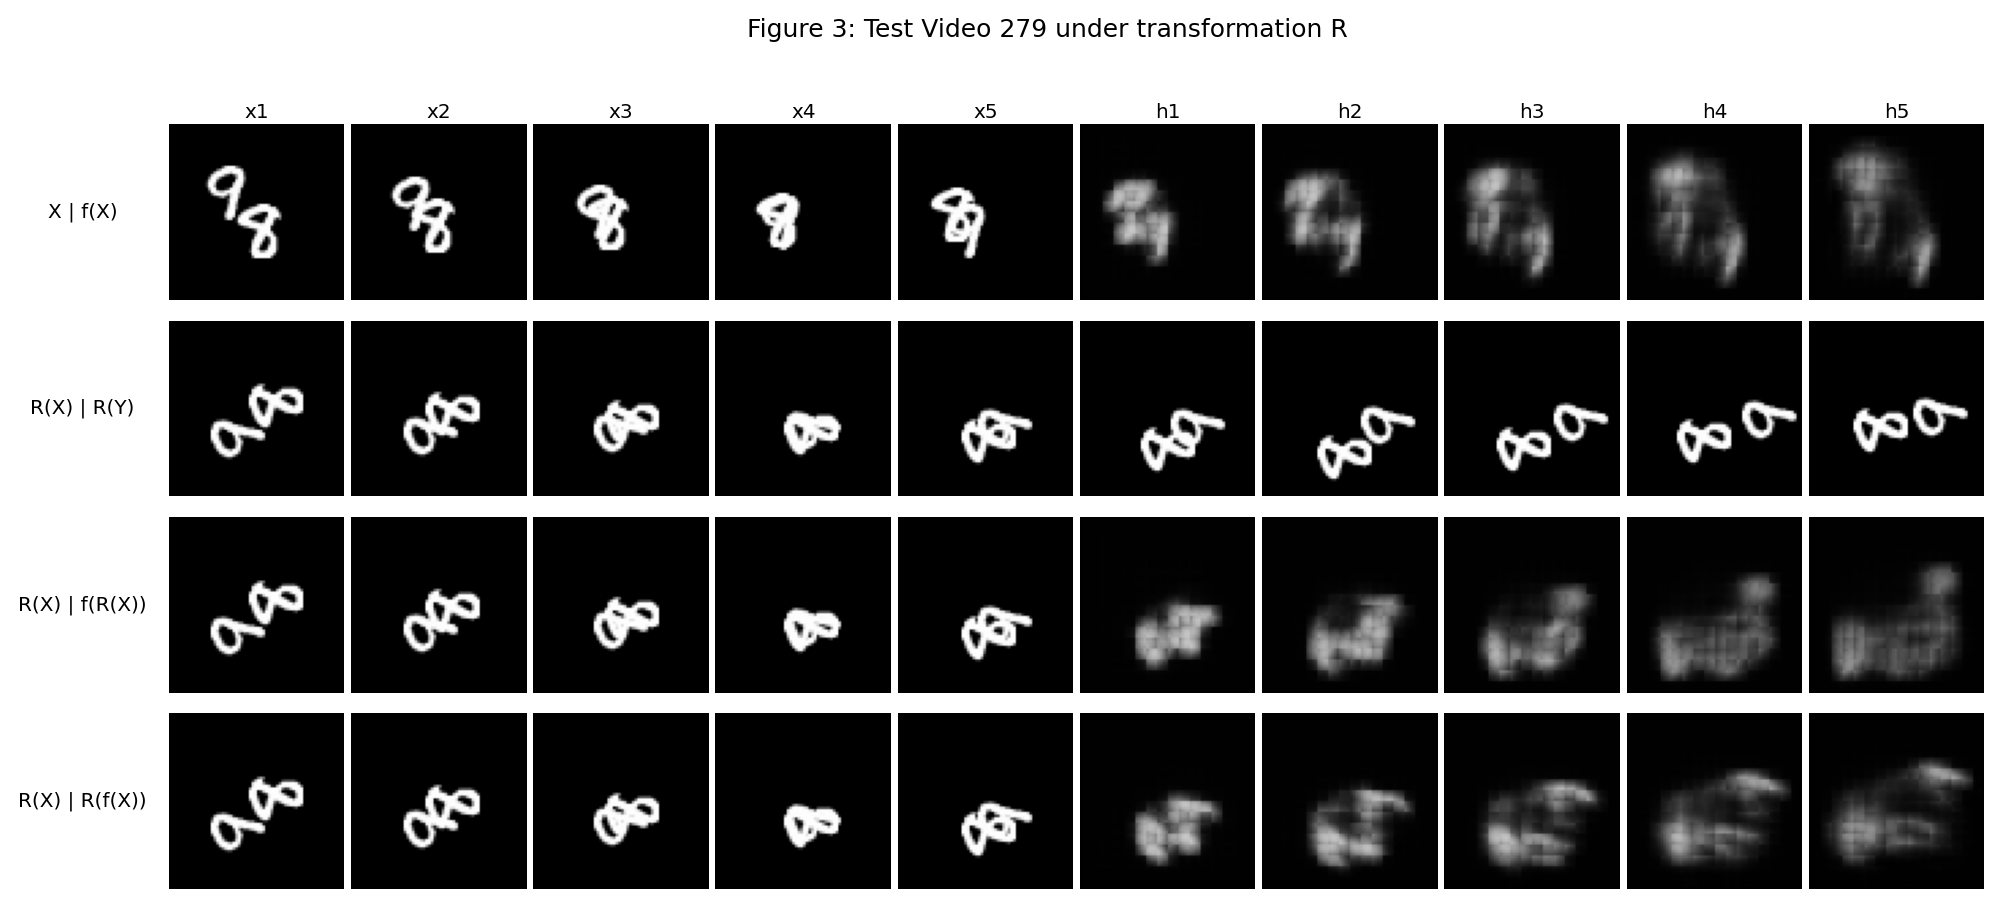

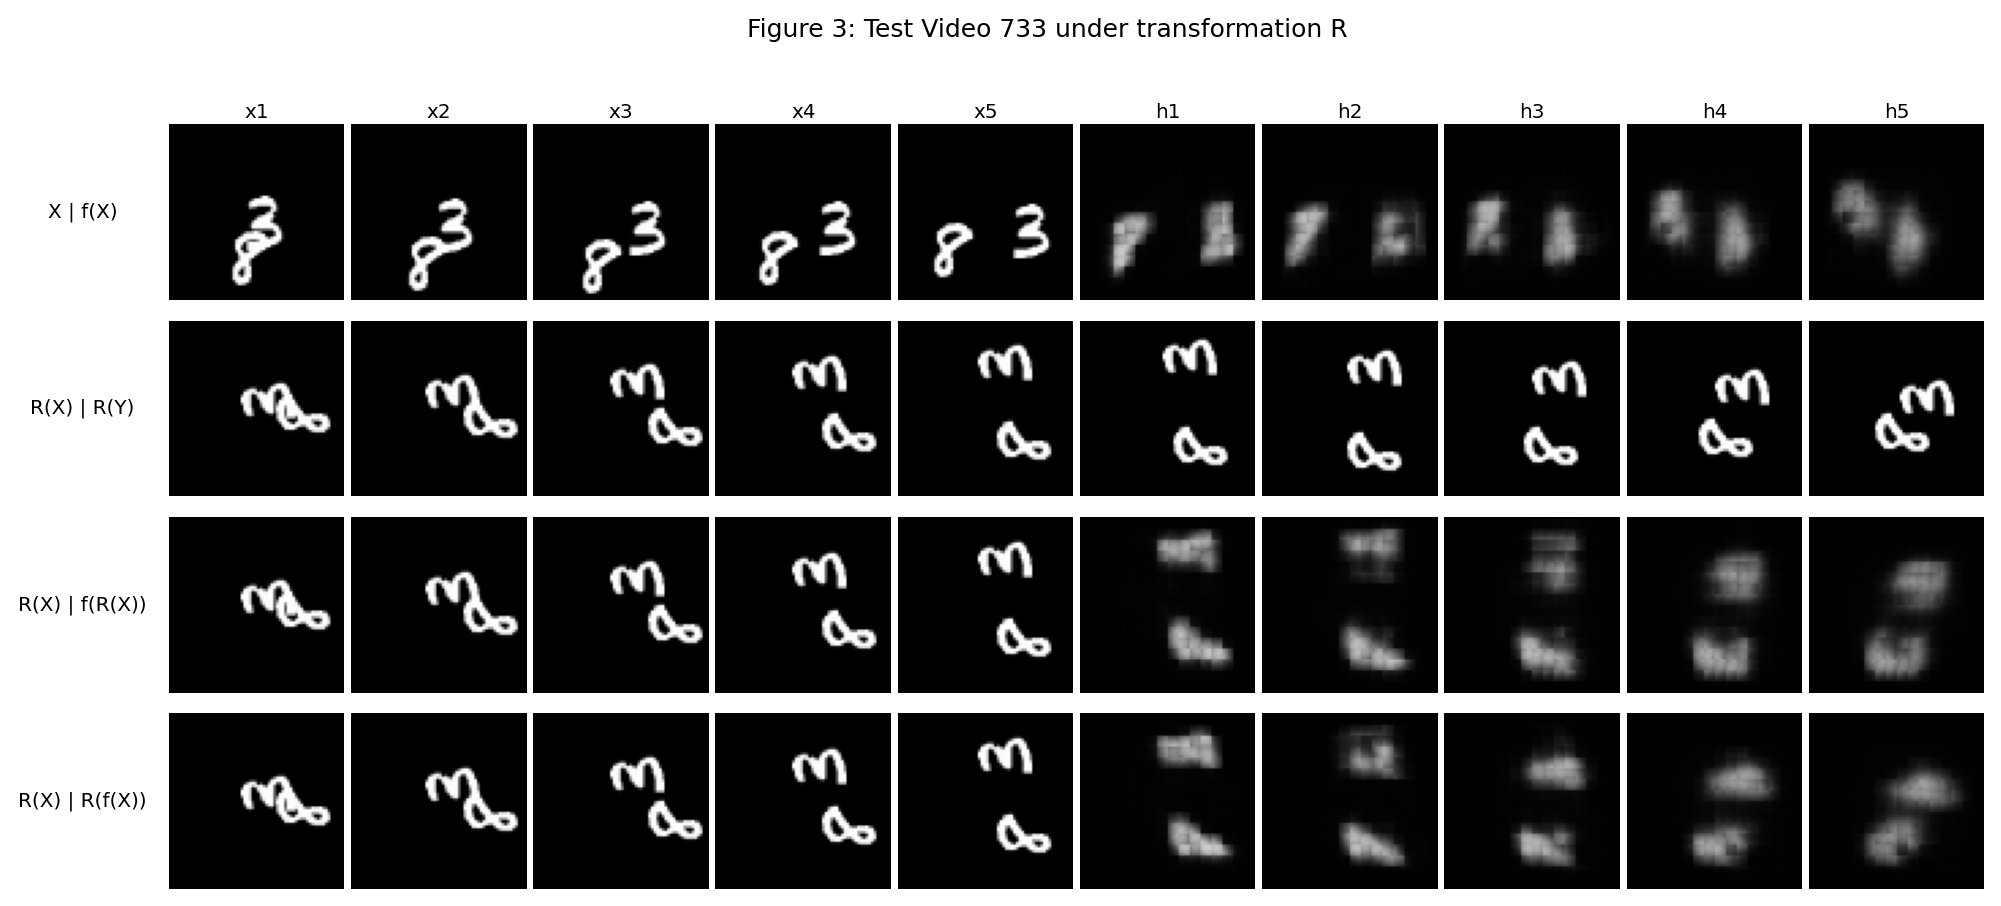

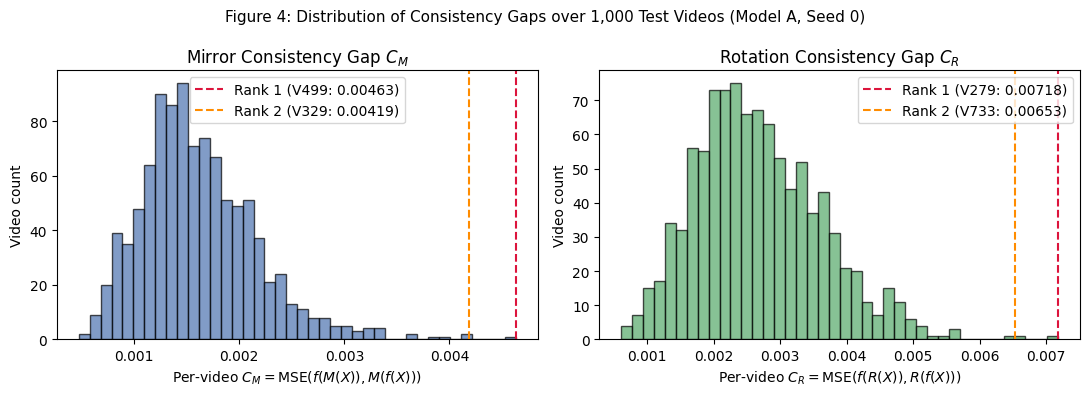

In [ ]:
# Figures 3 and 4: seed-0 model A, the two videos with the largest per-video C_M and C_R
pv = EV[("A", 0)][0]
TOP = {T: np.argsort(pv[f"C_{T}_pv"])[-2:][::-1].tolist() for T in ("M", "R")}
for T, vids in TOP.items():
    print(f"Top-2 C_{T} videos: {vids} (values: {[float(pv[f'C_{T}_pv'][v]) for v in vids]})")


def figure3_panels(model, prefix, fig_name):
    """One Figure 3 / 6a panel and GIF per top video, for model `model`."""
    for T, vids in TOP.items():
        P = predict(model, X1[vids], device)
        PT = predict(model, TRANSFORMS[T](X1[vids]), device)
        for rank, v in enumerate(vids):
            stem = f"{prefix}_{T}_top{rank + 1}_video{v}"
            make_figure3_panel(v, X1[v], Y1[v], P[rank], PT[rank], T,
                               FIG_DIR / f"{stem}.png", GIF_DIR / f"{stem}.gif", fig_name)
            display(Image(str(FIG_DIR / f"{stem}.png")))


figure3_panels(A0, "figure3", "Figure 3")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, T, color in zip(axes, ("M", "R"), ("#4c72b0", "#55a868")):
    c = pv[f"C_{T}_pv"]
    ax.hist(c, bins=40, color=color, edgecolor="k", alpha=0.7)
    for rank, v in enumerate(TOP[T]):
        ax.axvline(c[v], color="crimson" if rank == 0 else "darkorange", ls="--",
                   label=f"Rank {rank + 1} (V{v}: {c[v]:.3g})")
    ax.set(xlabel=f"Per-video $C_{T} = \\mathrm{{MSE}}(f({T}(X)), {T}(f(X)))$", ylabel="Video count",
           title=("Mirror" if T == "M" else "Rotation") + f" Consistency Gap $C_{T}$")
    ax.legend()
fig.suptitle("Figure 4: Distribution of Consistency Gaps over 1,000 Test Videos (Model A, Seed 0)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "figure4_consistency_histograms.png", dpi=180)
plt.show()

### 3.2 Faster Motion Evaluation (Table 4 & Figure 5)

Table 4 (test split, t = 1). Model A: mean (seed 0, seed 1).


,Model,E(2) 1×,E(2) 2×,E(2) 3×,E(5) 1×,E(5) 2×
0,Blank,0.0426,0.0425,0.0426,0.0426,0.0425
1,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719
2,Model A,"0.0188 (0.0192, 0.0185)","0.0447 (0.0435, 0.0459)","0.0519 (0.0509, 0.0529)","0.0222 (0.0225, 0.0219)","0.0492 (0.0476, 0.0509)"


Figure 5 video: 38; its two digits are separate in every displayed frame [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 16, 19]


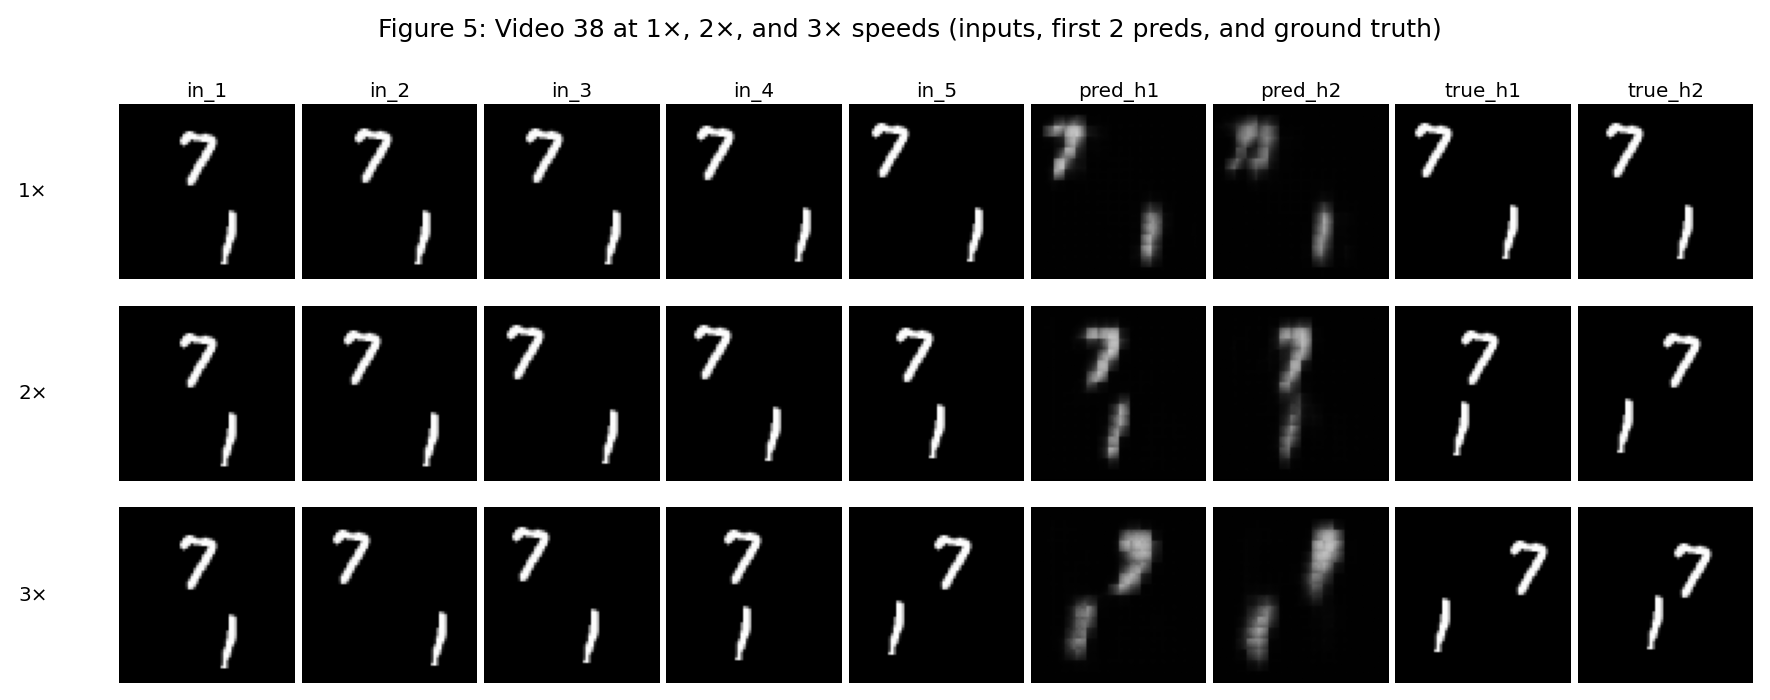

In [ ]:
# Table 4 and Figure 5: model A at 2x and 3x (t = 1), Blank and Copy-last for comparison
KEYS4 = ["E2_1x", "E2_2x", "E2_3x", "E5_1x", "E5_2x"]
t4 = {name: {k: EV[(name, None)][1][k] for k in KEYS4} for name in REFS}
t4["Model A"] = [dict(seed=s, **{k: EV[("A", s)][1][k] for k in KEYS4}) for s in SEEDS]
save_json("table4.json", t4)

rows = [[name] + [fmt(t4[name][k]) for k in KEYS4] for name in REFS]
rows.append(["Model A"] + [fmt_seeds([d[k] for d in t4["Model A"]]) for k in KEYS4])
print("Table 4 (test split, t = 1). Model A: mean (seed 0, seed 1).")
display(pd.DataFrame(rows, columns=["Model", "E(2) 1×", "E(2) 2×", "E(2) 3×", "E(5) 1×", "E(5) 2×"]))

fig5_video = first_clean_video(test_vids)
print(f"Figure 5 video: {fig5_video}; its two digits are separate in every displayed frame {figure5_frames()}")
make_figure5(A0, test_vids, fig5_video)
display(Image("figures/figure5_speeds.png"))

---
## 4. What Can Data Fix? (Models B, C, and D)

| Model | Architecture | Training speeds | Symmetry augmentation |
|---|---|---|---|
| A | baseline | $1\times$ only | none |
| B | baseline | $1\times$ only | $g$ uniform from $G$ |
| C | baseline | $k$ uniform from $\{1, 2, 3\}$ | none |
| D | larger reach (D3, Section 4.1) | $k$ uniform from $\{1, 2, 3\}$ | none |

B is A trained on randomly flipped and rotated clips, C is A trained on random speeds ($1\times$ to $3\times$), and D has a larger reach and is trained like C. D+B (optional) was **not** trained (see Section 5).


### 4.1 Model D Architecture & Reach

In [ ]:
# Model D (D3): parameters and reach, analytic and empirical; the other candidates for comparison
model_d = build("D")
assert n_params(model_d) <= 721_176 and model_d.reach_pixels() > 8
print(f"Model D ({D_CHOICE}): {n_params(model_d):,} parameters (limit 721,176), "
      f"reach {model_d.reach_pixels()} px (model A: 8 px)")
print(f"Empirical reach of D per input source (px): {empirical_reach(model_d)}")
for name in D_CANDIDATES:
    m = build(name)
    print(f"Candidate {name}: {n_params(m):,} parameters, reach {m.reach_pixels()} px")

Model D (D3): 709,520 parameters (limit 721,176), reach 16 px (model A: 8 px)
Empirical reach of D per input source (px): {'u_tau': 16, 'h1_prev': 16, 'c1_prev': 8, 'h2_prev': 8, 'c2_prev': 0}
Candidate D1: 480,784 parameters, reach 12 px
Candidate D2: 694,740 parameters, reach 12 px
Candidate D3: 709,520 parameters, reach 16 px
Candidate D4: 594,496 parameters, reach 16 px


In [ ]:
# Train models B, C, D (seeds 0, 1) only if a checkpoint is missing
for m_name in ("B", "C", "D"):
    for s in SEEDS:
        train_if_missing(m_name, s)

[B_s0] params=480784 reach=8px speed_aug=False sym_aug=True device=cuda
[B_s0] epoch  1 loss 0.04610 val E5 0.03931 time 2.0s
[B_s0] epoch  2 loss 0.03968 val E5 0.03853 time 2.0s
[B_s0] epoch  3 loss 0.03865 val E5 0.03737 time 2.0s
[B_s0] epoch  4 loss 0.03710 val E5 0.03579 time 2.0s
[B_s0] epoch  5 loss 0.03523 val E5 0.03395 time 2.2s
[B_s0] epoch  6 loss 0.03359 val E5 0.03224 time 2.2s
[B_s0] epoch  7 loss 0.03239 val E5 0.03140 time 2.2s
[B_s0] epoch  8 loss 0.03140 val E5 0.03039 time 2.0s
[B_s0] epoch  9 loss 0.03052 val E5 0.03030 time 2.0s
[B_s0] epoch 10 loss 0.02994 val E5 0.02948 time 2.0s
[B_s0] epoch 11 loss 0.02936 val E5 0.02888 time 2.0s
[B_s0] epoch 12 loss 0.02895 val E5 0.02868 time 2.0s
[B_s0] epoch 13 loss 0.02862 val E5 0.02812 time 2.0s
[B_s0] epoch 14 loss 0.02814 val E5 0.02758 time 2.0s
[B_s0] epoch 15 loss 0.02769 val E5 0.02725 time 2.0s
[B_s0] epoch 16 loss 0.02733 val E5 0.02683 time 2.0s
[B_s0] epoch 17 loss 0.02705 val E5 0.02677 time 2.0s
[B_s0] epo

### 4.2 Training Runs
All eight runs (models A–D, seeds 0 and 1) used Adam (learning rate $10^{-3}$, no schedule), batch 32 and 30 epochs, keeping the final-epoch weights, on one NVIDIA RTX PRO 6000. The validation split was used only to watch training. **D seed 0 collapsed**: from epoch 2 its training loss stays at 0.0402 and its validation error at 0.0395, the error of always predicting the same grey frame. D seed 1 reached the same plateau at epoch 2 and left it slowly from epoch 3. I kept D3 and report both seeds.

,run,model,arch,seed,params,reach (px),hardware,epochs,s / epoch,final train loss,final val E5 (1x)
0,A_s0,A,A,0,"480,784",8,NVIDIA RTX PRO 6000 Blackwell Server Edition,30,1.86,0.0225,0.0222
1,A_s1,A,A,1,"480,784",8,NVIDIA RTX PRO 6000 Blackwell Server Edition,30,1.77,0.0217,0.0218
2,B_s0,B,A,0,"480,784",8,NVIDIA RTX PRO 6000 Blackwell Server Edition,30,2.02,0.0229,0.0228
3,B_s1,B,A,1,"480,784",8,NVIDIA RTX PRO 6000 Blackwell Server Edition,30,2.00,0.0219,0.0220
4,C_s0,C,A,0,"480,784",8,NVIDIA RTX PRO 6000 Blackwell Server Edition,30,1.78,0.0303,0.0267
5,C_s1,C,A,1,"480,784",8,NVIDIA RTX PRO 6000 Blackwell Server Edition,30,1.77,0.0297,0.0258
6,D_D3_s0,D,D3,0,"709,520",16,NVIDIA RTX PRO 6000 Blackwell Server Edition,30,2.01,0.0402,0.0395
7,D_D3_s1,D,D3,1,"709,520",16,NVIDIA RTX PRO 6000 Blackwell Server Edition,30,2.01,0.0287,0.0270


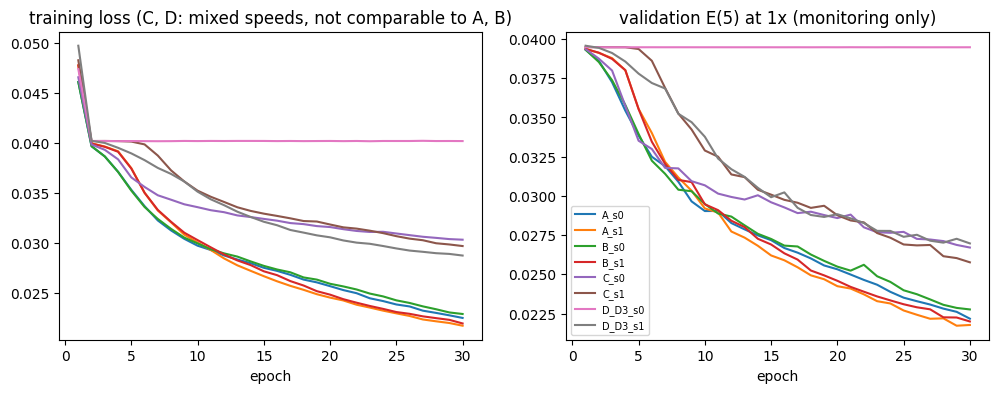

In [ ]:
# Training logs of all eight runs (written by q2.train.train): summary, curves and the full per-epoch log
LOGS = {Path(f).stem: json.load(open(f)) for f in sorted(glob.glob(str(LOG_DIR / "*.json")))}
display(pd.DataFrame([{
    "run": name, "model": d["model"], "arch": d["arch"], "seed": d["seed"],
    "params": f"{d['params']:,}", "reach (px)": d["reach_px"], "hardware": d["hardware"],
    "epochs": len(d["epochs"]), "s / epoch": fmt(d["train_time_per_epoch_s"]),
    "final train loss": fmt(d["epochs"][-1]["train_loss"]),
    "final val E5 (1x)": fmt(d["epochs"][-1]["val_E5_1x"]),
} for name, d in LOGS.items()]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, d in LOGS.items():
    ep = [e["epoch"] for e in d["epochs"]]
    ax[0].plot(ep, [e["train_loss"] for e in d["epochs"]], label=name)
    ax[1].plot(ep, [e["val_E5_1x"] for e in d["epochs"]], label=name)
ax[0].set(title="training loss (C, D: mixed speeds, not comparable to A, B)", xlabel="epoch")
ax[1].set(title="validation E(5) at 1x (monitoring only)", xlabel="epoch")
ax[1].legend(fontsize=7)
plt.show()

In [ ]:
# Full per-epoch training log of every run
for name, d in LOGS.items():
    print(f"[{name}] arch={d['arch']} params={d['params']} reach={d['reach_px']}px "
          f"speed_aug={PROTOCOLS[d['model']][0]} sym_aug={PROTOCOLS[d['model']][1]} hardware={d['hardware']}")
    for e in d["epochs"]:
        print(f"[{name}] epoch {e['epoch']:2d} loss {e['train_loss']:.5f} "
              f"val E5 {e['val_E5_1x']:.5f} time {e['time_s']:.1f}s")
    print(f"[{name}] done. mean epoch time {d['train_time_per_epoch_s']:.1f}s\n")

[A_s0] arch=A params=480784 reach=8px speed_aug=False sym_aug=False hardware=NVIDIA RTX PRO 6000 Blackwell Server Edition
[A_s0] epoch  1 loss 0.04611 val E5 0.03931 time 3.9s
[A_s0] epoch  2 loss 0.03967 val E5 0.03861 time 1.8s
[A_s0] epoch  3 loss 0.03865 val E5 0.03724 time 1.8s
[A_s0] epoch  4 loss 0.03712 val E5 0.03543 time 1.8s
[A_s0] epoch  5 loss 0.03531 val E5 0.03384 time 1.8s
[A_s0] epoch  6 loss 0.03367 val E5 0.03249 time 1.8s
[A_s0] epoch  7 loss 0.03224 val E5 0.03189 time 1.8s
[A_s0] epoch  8 loss 0.03124 val E5 0.03090 time 1.8s
[A_s0] epoch  9 loss 0.03040 val E5 0.02965 time 1.8s
[A_s0] epoch 10 loss 0.02971 val E5 0.02903 time 1.8s
[A_s0] epoch 11 loss 0.02928 val E5 0.02904 time 1.8s
[A_s0] epoch 12 loss 0.02873 val E5 0.02827 time 1.8s
[A_s0] epoch 13 loss 0.02833 val E5 0.02786 time 1.8s
[A_s0] epoch 14 loss 0.02796 val E5 0.02748 time 1.8s
[A_s0] epoch 15 loss 0.02750 val E5 0.02718 time 1.8s
[A_s0] epoch 16 loss 0.02719 val E5 0.02668 time 1.8s
[A_s0] epoch 1

### 4.3 The Window Samplers Follow the Rules

In [ ]:
# Window-sampler check: one epoch's worth of windows per protocol (sampling only, no training)
for m_name in ("A", "B", "C", "D"):
    sampler = WindowSampler(*PROTOCOLS[m_name], torch.Generator().manual_seed(0))
    ks, ts, gs, n_avail = [], [], [], []
    for i in range(0, len(train_u8), 32):
        _, _, mask, meta = sampler.sample(train_u8[i:i + 32])
        ks += meta["k"].tolist()
        ts += meta["t"].tolist()
        n_avail += mask.sum(1).int().tolist()
        if meta["g"] is not None:
            gs += meta["g"].tolist()
    print(f"Model {m_name}: k counts {dict(sorted(Counter(ks).items()))}")
    for k in sorted(set(ks)):
        t_k = sorted({t for t, kk in zip(ts, ks) if kk == k})
        avail = sorted({a for a, kk in zip(n_avail, ks) if kk == k})
        print(f"   k={k}: t in {t_k[0]}..{t_k[-1]} ({len(t_k)} values), available targets {avail}")
    if gs:
        print(f"   g counts {[Counter(gs)[i] for i in range(8)]} over {G_NAMES}")

Model A: k counts {1: 8000}
   k=1: t in 1..11 (11 values), available targets [5]
Model B: k counts {1: 8000}
   k=1: t in 1..11 (11 values), available targets [5]
   g counts [996, 991, 1000, 1027, 994, 991, 1001, 1000] over ['R0', 'R1', 'R2', 'R3', 'MR0', 'MR1', 'MR2', 'MR3']
Model C: k counts {1: 2702, 2: 2603, 3: 2695}
   k=1: t in 1..14 (14 values), available targets [2, 3, 4, 5]
   k=2: t in 1..8 (8 values), available targets [2, 3, 4, 5]
   k=3: t in 1..2 (2 values), available targets [2]
Model D: k counts {1: 2702, 2: 2603, 3: 2695}
   k=1: t in 1..14 (14 values), available targets [2, 3, 4, 5]
   k=2: t in 1..8 (8 values), available targets [2, 3, 4, 5]
   k=3: t in 1..2 (2 values), available targets [2]


In [ ]:
# Table 5: models A-D, both seeds
KEYS5 = ["E5_1x", "C_M", "E_M", "C_R", "E_R", "E2_1x", "E2_2x", "E2_3x"]
COLS5 = ["E(5) 1x", "C_M", "E_M", "C_R", "E_R", "E(2) 1x", "E(2) 2x", "E(2) 3x"]


def seed_records(name, make_model, log_name):
    """One record per seed: Table 5/6 metrics, parameters, training and inference time."""
    recs = []
    for s in SEEDS:
        model = make_model(s)
        scal = evaluate(name, s, model)[1]
        recs.append(dict(seed=s, params=n_params(model), **{k: scal[k] for k in KEYS5},
                         train_t_epoch=LOGS[f"{ckpt_stem(log_name)}_s{s}"]["train_time_per_epoch_s"],
                         inference_time=inference_time(model, device)))
    return recs


def seed_table(table):
    return pd.DataFrame([[name] + [fmt_seeds([r[k] for r in recs]) for k in KEYS5]
                         + [f"{recs[0]['params']:,}",
                            fmt_seeds([r["train_t_epoch"] for r in recs]) + " s",
                            fmt_seeds([r["inference_time"] for r in recs]) + " s"]
                         for name, recs in table.items()],
                        columns=["Model"] + COLS5 + ["Params", "Train/ep", "Infer t"])


t5 = {m: seed_records(m, lambda s, m=m: load_model(m, s), m) for m in ("A", "B", "C", "D")}
save_json("table5.json", dict(t5, inference_hardware=hardware_string(device)))
print("Table 5 (test split). Entries are mean (seed 0, seed 1).")
display(seed_table(t5))
print(f"Train/ep: mean over 30 epochs, trained on {', '.join(sorted({d['hardware'] for d in LOGS.values()}))} (see 4.2).")
print(f"Infer t: all 1,000 test videos (1x, t=1), batch 32, measured on {hardware_string(device)}.")

Table 5 (test split). Entries are mean (seed 0, seed 1).


,Model,E(5) 1x,C_M,E_M,C_R,E_R,E(2) 1x,E(2) 2x,E(2) 3x,Params,Train/ep,Infer t
0,A,"0.0222 (0.0225, 0.0219)","0.00186 (0.00161, 0.00211)","0.0228 (0.0230, 0.0225)","0.00298 (0.00268, 0.00329)","0.0239 (0.0240, 0.0238)","0.0188 (0.0192, 0.0185)","0.0447 (0.0435, 0.0459)","0.0519 (0.0509, 0.0529)","480,784","1.81 (1.86, 1.77) s","0.0609 (0.0608, 0.0609) s"
1,B,"0.0226 (0.0230, 0.0222)","0.00123 (0.00117, 0.00128)","0.0226 (0.0230, 0.0222)","0.00147 (0.00148, 0.00146)","0.0224 (0.0228, 0.0221)","0.0189 (0.0192, 0.0186)","0.0443 (0.0445, 0.0440)","0.0509 (0.0509, 0.0509)","480,784","2.01 (2.02, 2.00) s","0.0609 (0.0608, 0.0609) s"
2,C,"0.0265 (0.0270, 0.0260)","0.00134 (0.00141, 0.00128)","0.0267 (0.0272, 0.0262)","0.00257 (0.00270, 0.00245)","0.0276 (0.0280, 0.0272)","0.0231 (0.0237, 0.0225)","0.0285 (0.0289, 0.0282)","0.0333 (0.0334, 0.0333)","480,784","1.78 (1.78, 1.77) s","0.0609 (0.0608, 0.0609) s"
3,D,"0.0336 (0.0401, 0.0271)","6.18e-04 (2.68e-07, 0.00124)","0.0338 (0.0401, 0.0274)","0.00119 (6.94e-07, 0.00238)","0.0342 (0.0401, 0.0284)","0.0323 (0.0402, 0.0245)","0.0338 (0.0401, 0.0276)","0.0355 (0.0402, 0.0308)","709,520","2.01 (2.01, 2.01) s","0.0614 (0.0613, 0.0615) s"


Train/ep: mean over 30 epochs, trained on NVIDIA RTX PRO 6000 Blackwell Server Edition (see 4.2).
Infer t: all 1,000 test videos (1x, t=1), batch 32, measured on NVIDIA RTX PRO 6000 Blackwell Server Edition.


---
## 5. The Final Model: Exact Equivariance via Symmetrization

### Which Model Is Final, and Which Seed Figure 6 Shows
**Built-in symmetry.** The symmetrised model runs the base model on all 8 flipped and rotated versions of a clip, undoes each transformation and averages. Transforming the input first only reorders those 8 terms, so the output transforms in exactly the same way, whatever the weights: $C_M = C_R = 0$ (up to rounding). **Final model: symmetrised D**, since it is the only model trained for fast motion; D+B was not trained because the wrapper already gives what B's training adds. Figure 6 uses **seed 1**, because seed 0 collapsed and would show only grey frames.


In [ ]:
# Table 6: symmetrised B and symmetrised D (the final model)
t6 = {f"Sym-{m}": seed_records(f"Sym-{m}", lambda s, m=m: Symmetrised(load_model(m, s)), m) for m in ("B", "D")}
save_json("table6.json", dict(t6, inference_hardware=hardware_string(device)))
print("Table 6 (test split). Entries are mean (seed 0, seed 1); C_M, C_R in scientific notation.")
display(seed_table(t6))
print("Train/ep: the underlying learned model's (B, D; see Table 5); symmetrisation needs no training.")
print(f"Infer t includes all 8 transforms, forward passes, inverse transforms and the averaging; "
      f"measured on {hardware_string(device)}.")

Table 6 (test split). Entries are mean (seed 0, seed 1); C_M, C_R in scientific notation.


,Model,E(5) 1x,C_M,E_M,C_R,E_R,E(2) 1x,E(2) 2x,E(2) 3x,Params,Train/ep,Infer t
0,Sym-B,"0.0219 (0.0223, 0.0216)","4.40e-17 (4.72e-17, 4.07e-17)","0.0219 (0.0223, 0.0216)","4.51e-17 (4.84e-17, 4.17e-17)","0.0219 (0.0223, 0.0216)","0.0184 (0.0186, 0.0182)","0.0434 (0.0438, 0.0431)","0.0498 (0.0500, 0.0497)","480,784","2.01 (2.02, 2.00) s","0.253 (0.255, 0.251) s"
1,Sym-D,"0.0336 (0.0401, 0.0270)","1.61e-17 (6.18e-18, 2.61e-17)","0.0336 (0.0401, 0.0270)","1.64e-17 (5.88e-18, 2.68e-17)","0.0336 (0.0401, 0.0270)","0.0323 (0.0402, 0.0244)","0.0338 (0.0401, 0.0274)","0.0354 (0.0402, 0.0306)","709,520","2.01 (2.01, 2.01) s","0.333 (0.337, 0.329) s"


Train/ep: the underlying learned model's (B, D; see Table 5); symmetrisation needs no training.
Infer t includes all 8 transforms, forward passes, inverse transforms and the averaging; measured on NVIDIA RTX PRO 6000 Blackwell Server Edition.


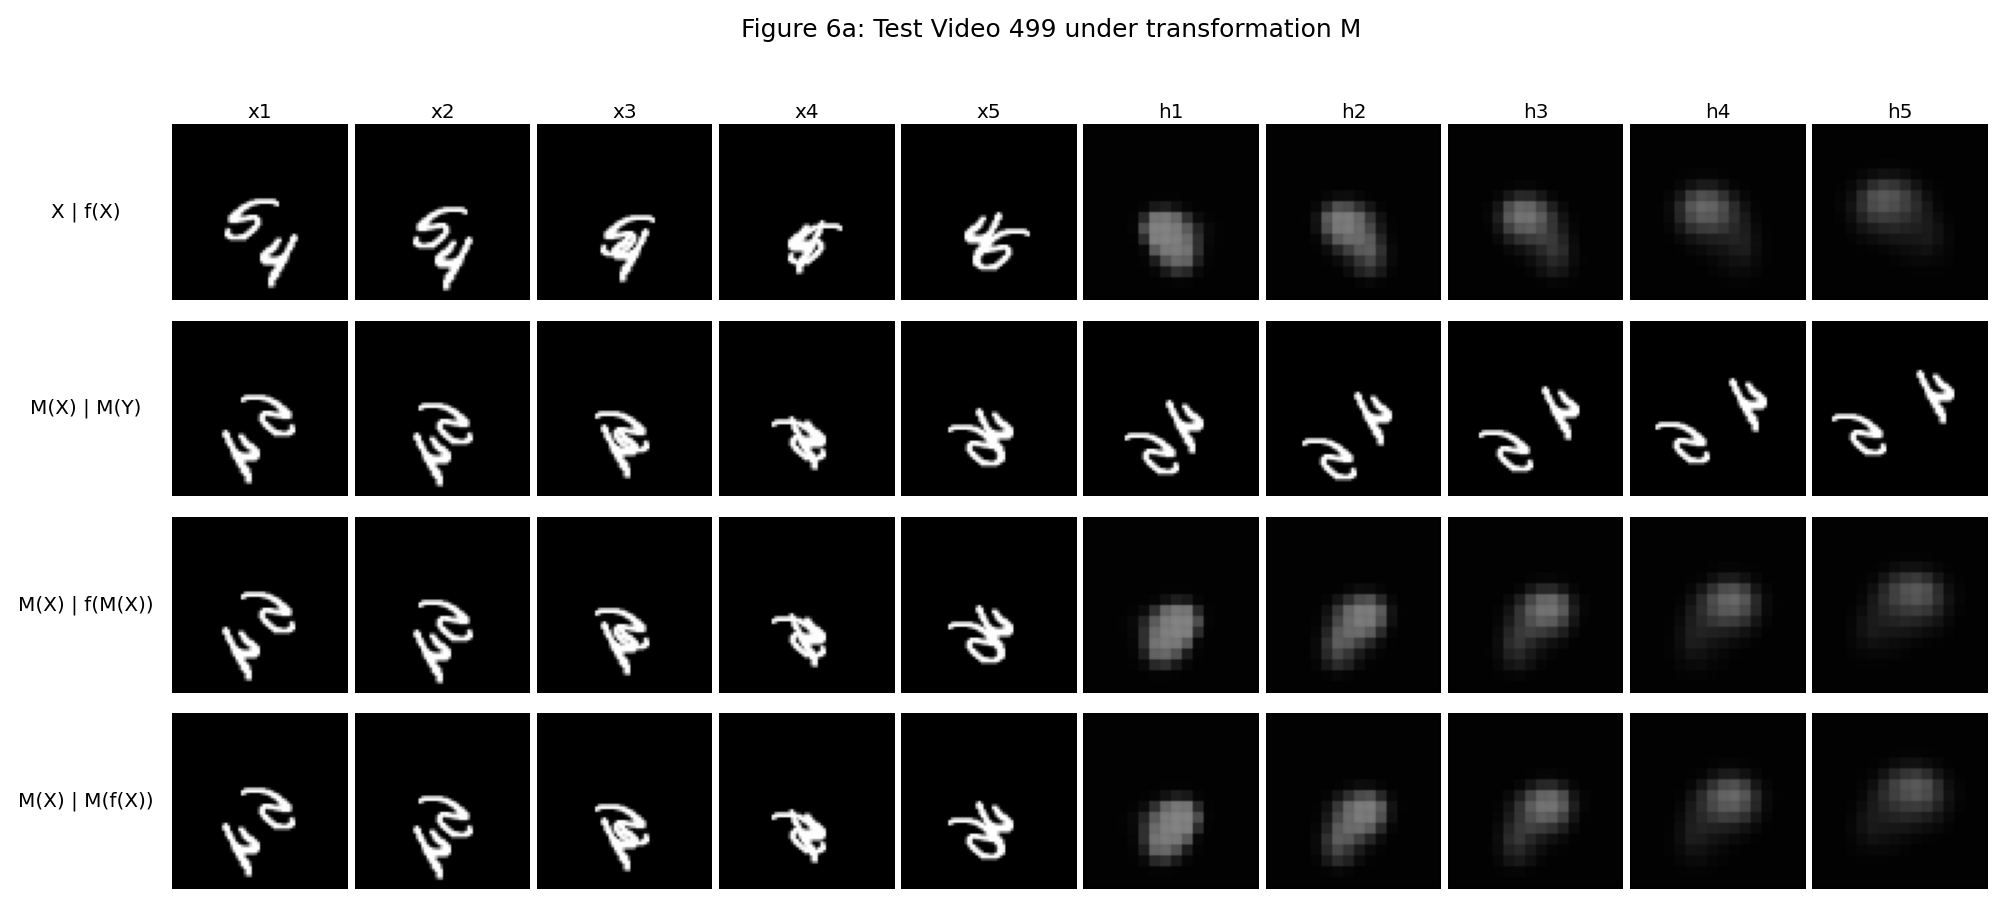

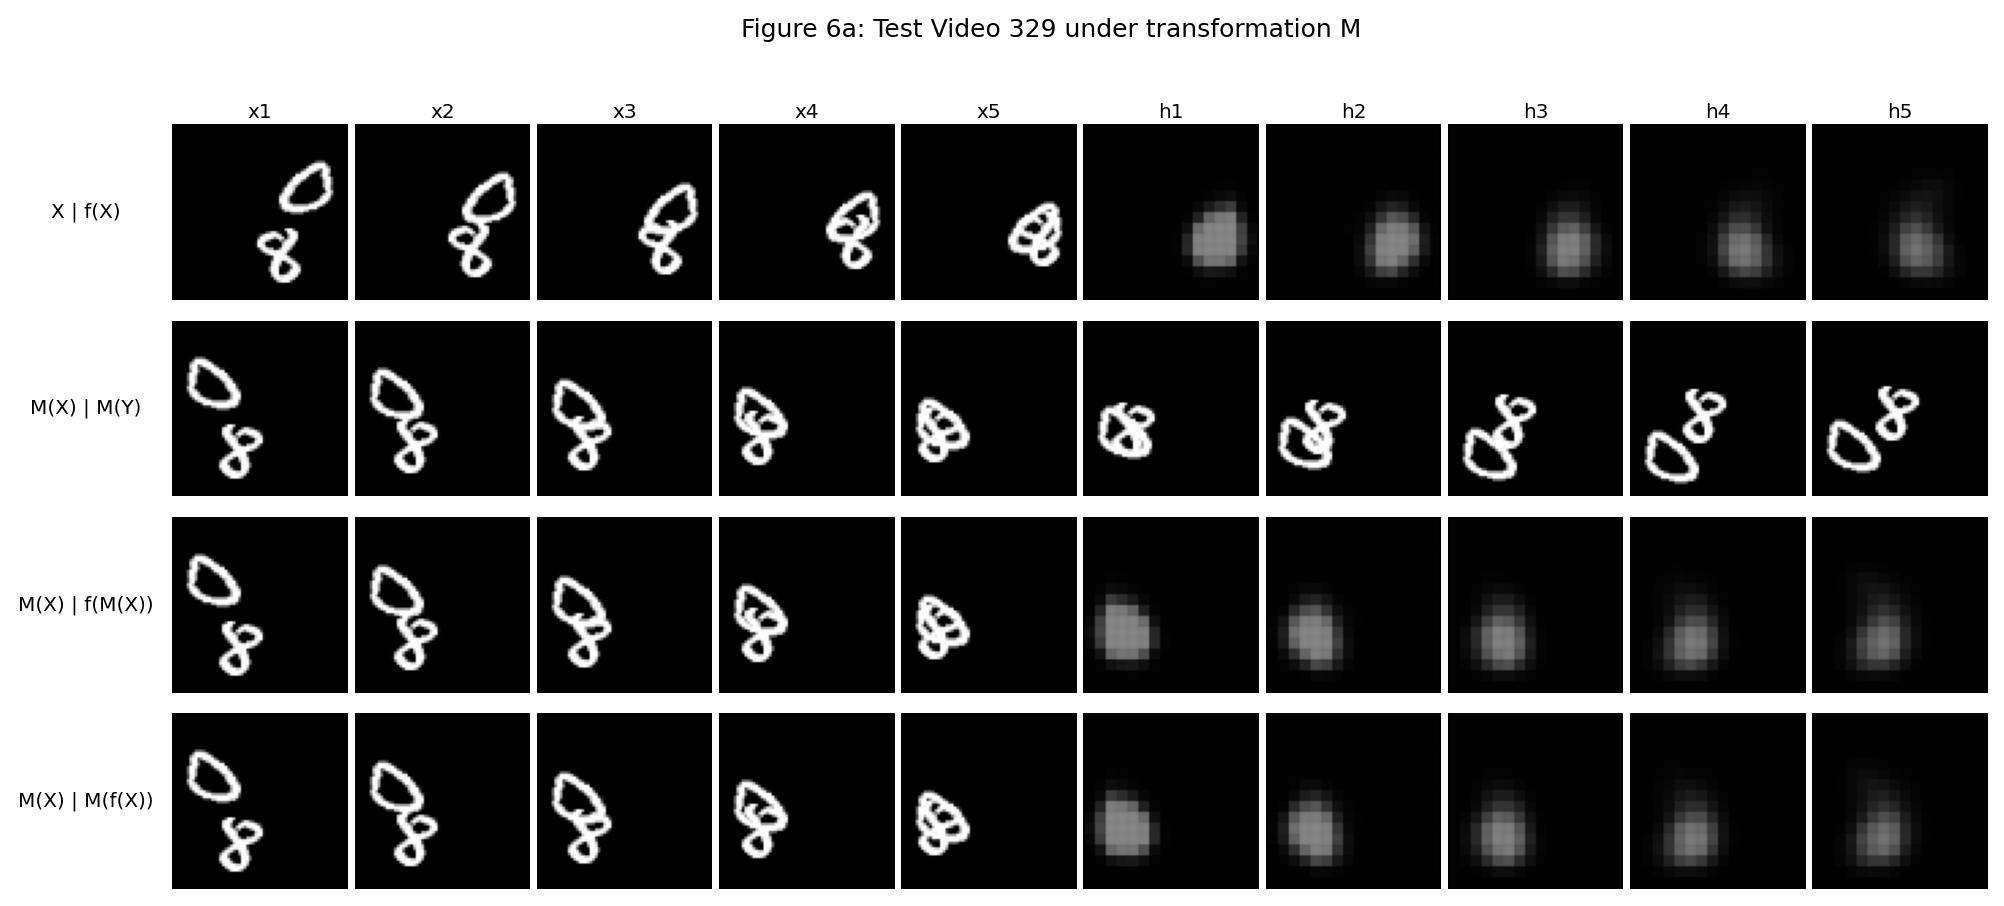

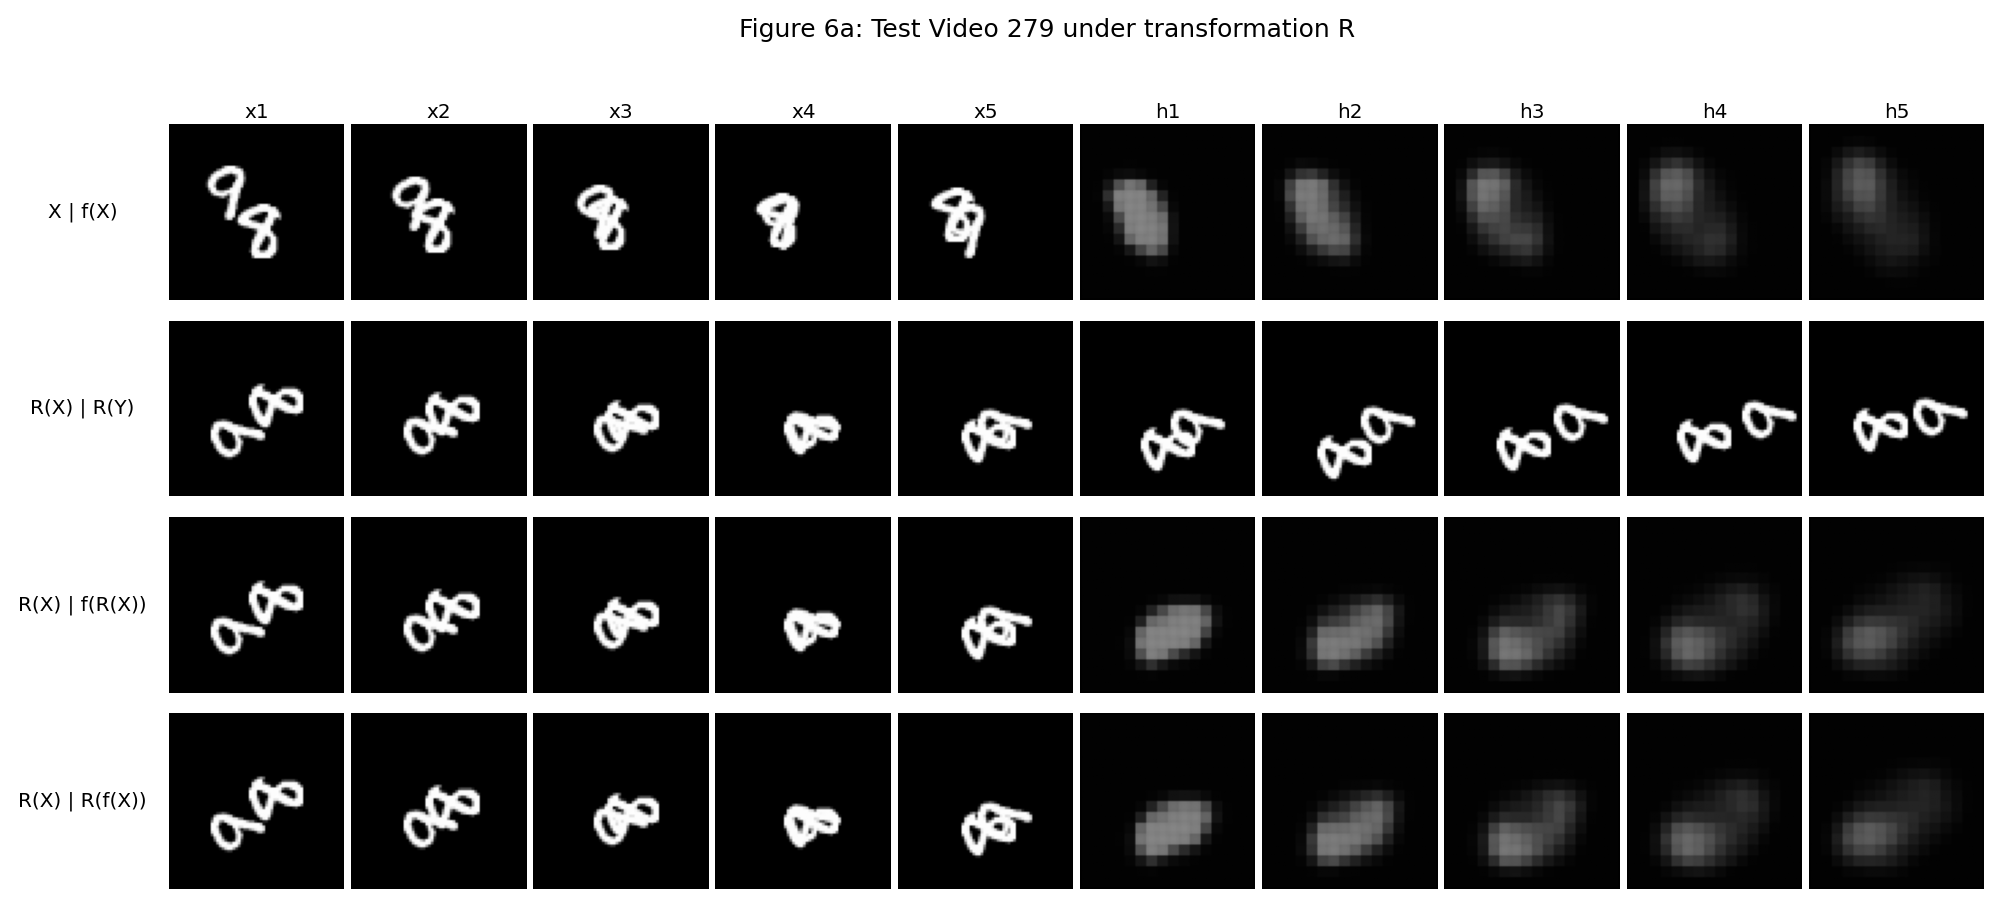

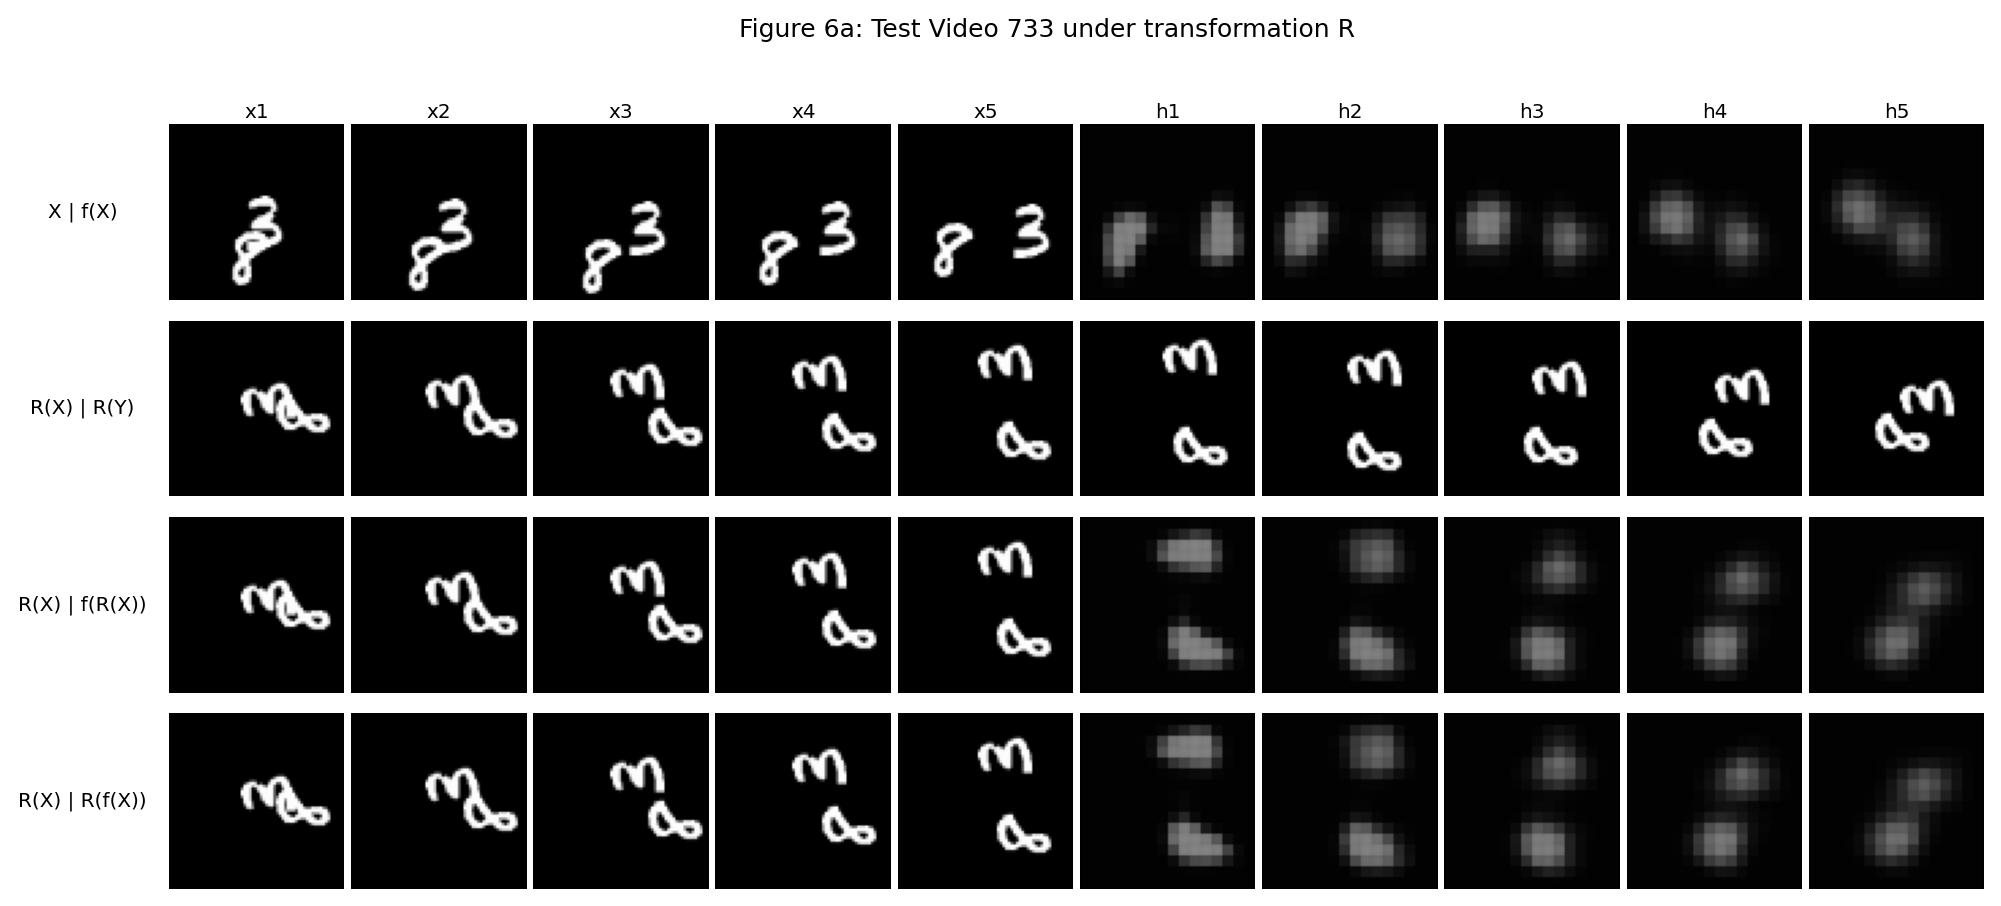

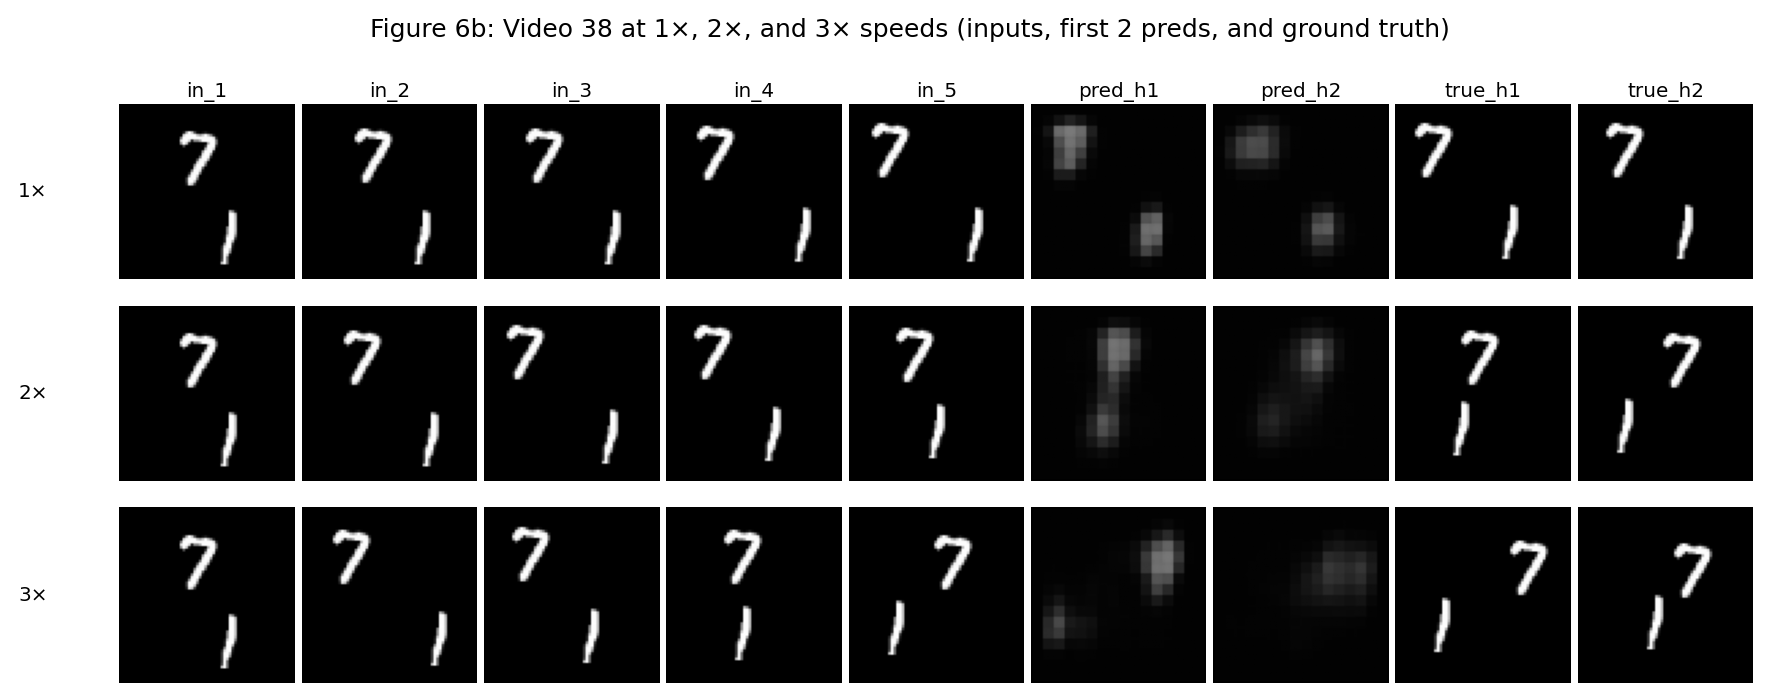

In [ ]:
# Figure 6: the final model (symmetrised D, seed 1 -- seed 0 collapsed, see Section 5) on the Figure 3 and 5 videos
final_model = Symmetrised(load_model("D", 1))
figure3_panels(final_model, "figure6a", "Figure 6a")
make_figure5(final_model, test_vids, fig5_video, FIG_DIR / "figure6b_speeds_final.png", "Figure 6b")
display(Image("figures/figure6b_speeds_final.png"))